In [44]:
# Zachary Katz
# zachary_katz@mines.edu
# 11 November 2026

"""
Programatically download n tracks of SWOT L3_LR_SSH_Expert data for all available
cycles, clean, and calculate tides in an harmonic inversion.
"""

# Imports
import altimetry_downloader_aviso
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
from cartopy import crs as ccrs

In [27]:
# Download SWOT
output_dir = "./_Data"
altimetry_downloader_aviso.get("SWOT_L3_LR_SSH_Expert", output_dir=output_dir, cycle_number=list(range(1,59)), pass_number=[201, 214, 479, 520])

['_Data/SWOT_L3_LR_SSH_Expert_030_520_20250404T202204_20250404T211331_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_031_201_20250414T073534_20250414T082700_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_031_214_20250414T184423_20250414T193550_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_031_479_20250424T055751_20250424T064918_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_031_520_20250425T170711_20250425T175837_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_032_201_20250505T042038_20250505T051205_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_032_214_20250505T152927_20250505T162053_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_032_479_20250515T024255_20250515T033421_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_032_520_20250516T135215_20250516T144341_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_033_201_20250526T010544_20250526T015710_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_033_214_20250526T121433_20250526T130600_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_033_479_20250604T232801_20250605T001927_v3.0.nc',
 '_Data/SWOT_L3_LR_SSH_Expert_033_520_20

In [33]:
# Load and inspect data
# Plot 1st cycle on map

data_paths = Path(output_dir).glob("SWOT_L3_LR_SSH_Expert_001*.nc")
data_df = [xr.open_dataset(path) for path in data_paths]

In [41]:
data_df[0]

<xarray.Dataset> Size: 99MB
Dimensions:               (num_lines: 9860, num_pixels: 69, num_nadir: 1548)
Coordinates:
    latitude              (num_lines, num_pixels) float64 5MB ...
    longitude             (num_lines, num_pixels) float64 5MB ...
Dimensions without coordinates: num_lines, num_pixels, num_nadir
Data variables: (12/21)
    time                  (num_lines) datetime64[ns] 79kB ...
    calibration           (num_lines, num_pixels) float64 5MB ...
    cross_track_distance  (num_pixels) float64 552B ...
    dac                   (num_lines, num_pixels) float64 5MB ...
    internal_tide         (num_lines, num_pixels) float64 5MB ...
    mdt                   (num_lines, num_pixels) float64 5MB ...
    ...                    ...
    ugosa_unfiltered      (num_lines, num_pixels) float64 5MB ...
    vgos_filtered         (num_lines, num_pixels) float64 5MB ...
    vgosa_filtered        (num_lines, num_pixels) float64 5MB ...
    vgosa_unfiltered      (num_lines, num_pixels) float64 5MB ...
    i_num_line            (num_nadir) int16 3kB ...
    i_num_pixel           (num_nadir) int8 2kB ...
Attributes: (12/43)
    Conventions:                     CF-1.9
    Metadata_Conventions:            Unidata Dataset Discovery v1.0
    cdm_data_type:                   Swath
    comment:                         Sea Surface Height measured by Altimetry
    data_used:                       SWOT KaRIn L2_LR_SSH PGC0/PIC0/PIC2/PID0...
    doi:                             https://doi.org/10.24400/527896/A01-2023...
    ...                              ...
    geospatial_lon_max:              359.99821
    date_modified:                   2025-11-24T16:55:03Z
    history:                         2025-11-24T16:55:03Z: Created by DUACS K...
    date_created:                    2025-11-24T16:55:03Z
    date_issued:                     2025-11-24T16:55:03Z
    temporality:                     reproc

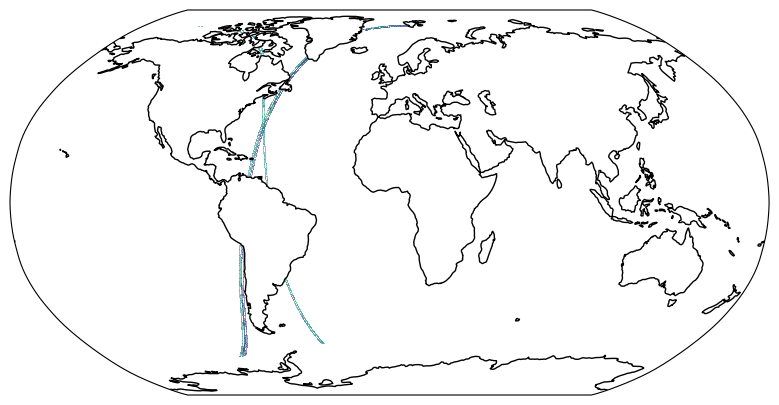

In [57]:
fig, ax = plt.subplots(figsize=(10, 5),subplot_kw={'projection': ccrs.Robinson()})
for df in data_df[:]:
    ax.pcolormesh(df['longitude'], df['latitude'], df['ssha_filtered'], shading='auto',transform=ccrs.PlateCarree(), cmap='viridis', alpha=0.5)
# Add coastlines
ax.coastlines()
ax.set_extent([-180, 180, -90, 90], crs=ccrs.PlateCarree())

In [ ]:
# Calculate tides and plot constitutents
